In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import InMemoryVectorStore
from langchain_groq import ChatGroq

from langgraph.graph import START, END, StateGraph
from pydantic import BaseModel, Field

In [6]:
## Load the docs
loader = PyPDFLoader("../data/Aditya_Goenka_Resume_Latest.pdf")
doc = loader.load()

## split the text
text_splitter = RecursiveCharacterTextSplitter(chunk_size = 1000, chunk_overlap = 200)
docs = text_splitter.split_documents(doc)

## embedding
embedding = OpenAIEmbeddings(model="text-embedding-3-large")

## store in vector db
vector_store = InMemoryVectorStore.from_documents(
    documents=docs,
    embedding=embedding
)


In [11]:
llm = ChatGroq(model="openai/gpt-oss-20b")

In [7]:
## question -> context -> generate -> answer

class RagState(BaseModel):
    question : str = Field(description="User question")
    documents: list = []
    context : str = Field(description="contect for LLM", default="")
    answer : str = Field(description="Answer from LLM", default="")


## create nodes
def get_documents_node(state:RagState) -> RagState:
    state.documents = vector_store.similarity_search(state.question)
    return state

def get_context_node(state:RagState) -> RagState:
    context =""
    for doc in state.documents:
        context += doc.page_content + "\n\n"
    state.context = context
    return state

def generate_answer_node(state:RagState) -> RagState:
    prompt = f"""
        you are an assisstant. answer the question based on the context provided. if you do not know the answer, just say i don't know
        context: {state.context}
        question: {state.question}
    """
    res = llm.invoke(prompt)
    state.answer = res.content
    return state

In [8]:
graph = StateGraph(RagState)

graph.add_node("get_documents_node", get_documents_node)
graph.add_node("get_context_node", get_context_node)
graph.add_node("generate_answer_node", generate_answer_node)

graph.add_edge(START, "get_documents_node")
graph.add_edge("get_documents_node", "get_context_node")
graph.add_edge("get_context_node", "generate_answer_node")
graph.add_edge("generate_answer_node", END)

graph = graph.compile()

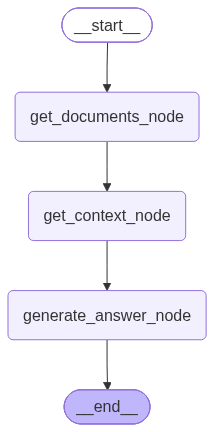

In [9]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())


In [15]:
response = graph.invoke({"question": "What is the highest education of the person"})

In [16]:
print(response["answer"])

Bachelor of Engineering (B.E.) from Thapar University.
